# ChokeBench v1: does your verifier find where a reasoning failure is decided?

Process reward models are trained to find the **first wrong step** of a chain of thought. But is that the step where
the failure is actually *decided*? For 469 failed maths traces from ProcessBench we resampled the generator 64
times from every prefix and measured v_k, its chance of still solving the problem from step k. The **choke point** is
the step where v_k collapses.

Finding: a PRM hits **73%** of human-labelled first errors but only **45%** of choke points, and the human label is
the choke point only about half the time.

Paper, code and all rollouts: [github.com/HarshDubey23/early-failure-detection-cot](https://github.com/HarshDubey23/early-failure-detection-cot) ·
Dataset: ChokeBench v1 (attach it from the Input panel).

In [1]:
import json, os, urllib.request
import numpy as np
import matplotlib.pyplot as plt

# Kaggle: attach the ChokeBench dataset. Elsewhere: falls back to the GitHub copy.
local = [os.path.join(d, f) for d, _, fs in os.walk("/kaggle/input") for f in fs if f == "chokebench_v1.jsonl"]
URL = "https://raw.githubusercontent.com/HarshDubey23/early-failure-detection-cot/main/results/chokebench/chokebench_v1.jsonl"
lines = open(local[0]).read().splitlines() if local else urllib.request.urlopen(URL).read().decode().splitlines()
rows = [json.loads(l) for l in lines]
print(len(rows), "failed traces;", rows[0].keys())

469 failed traces; dict_keys(['trace_id', 'generator', 'n_steps', 'human_first_error', 'successes', 'continuations', 'mean_continuation_tokens', 'prm', 'capability_limited'])


## What one trace looks like

Each line holds, per prefix, how many of 64 continuations still reached the right answer. The red line is the
human-labelled first error; the choke point is the steepest fall of v_k.

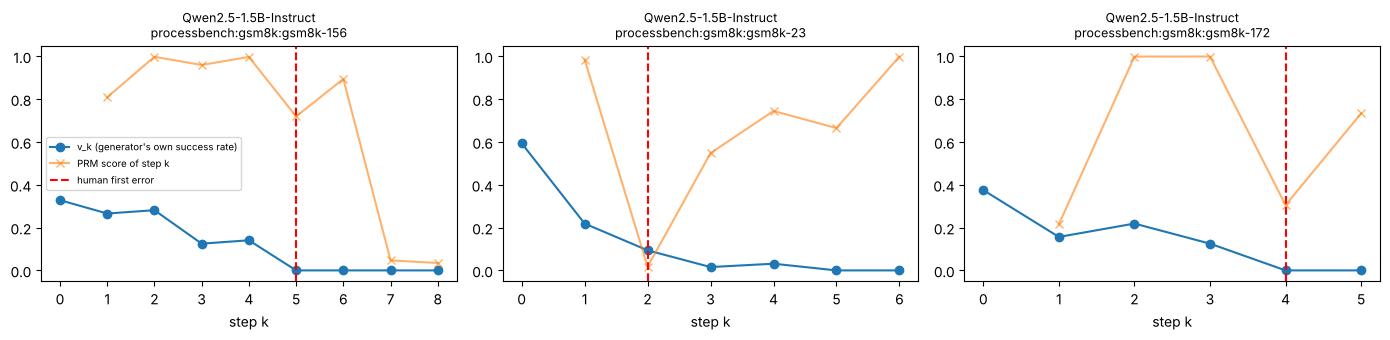

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, r in zip(axes, rows[:3]):
    v = np.r_[np.array(r["successes"]) / np.array(r["continuations"]), 0.0]
    ax.plot(range(len(v)), v, marker="o", label="v_k (generator's own success rate)")
    ax.plot(range(1, r["n_steps"] + 1), r["prm"], marker="x", alpha=.6, label="PRM score of step k")
    ax.axvline(r["human_first_error"], color="red", ls="--", label="human first error")
    ax.set_title(f'{r["generator"]}\n{r["trace_id"]}', fontsize=9); ax.set_xlabel("step k"); ax.set_ylim(-.05, 1.05)
axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## The scorer

Open traces only (not capability-limited, v_0 > 1/8). For each named step j:
- **acc_human**: j is the human first error;
- **acc_decisive**: posterior probability that j is the choke point (Jeffreys posterior on every v_k, so sampling
  noise is not a miss);
- **gain**: v_{j-1} − v_0, one attempt resampled before j minus one plain restart.

This skips the paper's sample-split weighting, so numbers sit within ~0.01 of the official table.

In [3]:
DELTA, N_POST = 0.125, 2000
open_rows = [r for r in rows if not r["capability_limited"]
             and r["successes"][0] / r["continuations"][0] > DELTA]

def posterior_choke(r, rng):
    s, c = np.array(r["successes"], float), np.array(r["continuations"], float)
    draws = np.hstack([rng.beta(s + .5, c - s + .5, size=(N_POST, len(s))), np.zeros((N_POST, 1))])
    return np.bincount(np.argmax(draws[:, :-1] - draws[:, 1:], axis=1), minlength=len(s)) / N_POST

def score(name_step, rows=open_rows):
    rng, h, d, g = np.random.default_rng(0), [], [], []
    for r in rows:
        j = name_step(r)
        if j is None or not 1 <= j <= r["n_steps"]:   # names no step: a miss, falls back to restart
            h.append(False); d.append(0.0); g.append(0.0); continue
        v = np.array(r["successes"]) / np.array(r["continuations"])
        h.append(j == r["human_first_error"]); d.append(posterior_choke(r, rng)[j - 1]); g.append(v[j - 1] - v[0])
    return dict(n=len(h), acc_human=np.mean(h), acc_decisive=np.mean(d), gain=np.mean(g))

print(len(open_rows), "open traces")

197 open traces


In [4]:
BASELINES = {
    "human first error": lambda r: r["human_first_error"],
    "PRM: first step < 0.5": lambda r: next((i + 1 for i, p in enumerate(r["prm"]) if p < .5), None),
    "PRM: largest drop": lambda r: int(np.argmax(np.r_[1.0, r["prm"][:-1]] - np.array(r["prm"]))) + 1,
    "PRM: minimum": lambda r: int(np.argmin(r["prm"])) + 1,
    "first step (= restart)": lambda r: 1,
}
print(f"{'localiser':24s} {'human':>6s} {'choke':>6s} {'gain':>7s}")
for k, f in BASELINES.items():
    s = score(f)
    print(f"{k:24s} {s['acc_human']:6.3f} {s['acc_decisive']:6.3f} {s['gain']:+7.3f}")

localiser                 human  choke    gain


human first error         1.000  0.519  -0.085


PRM: first step < 0.5     0.690  0.387  -0.092


PRM: largest drop         0.741  0.459  -0.123


PRM: minimum              0.609  0.404  -0.178


first step (= restart)    0.152  0.277  +0.000


## Try your own localiser

Write a function that takes a trace and returns one 1-based step. It may use `prm`, `n_steps` and
`mean_continuation_tokens`, but **not** `successes` or `continuations` (that is the answer key).

A starter: the PRM's largest drop, searched only in the first half of the chain. It loses less to restart than every PRM rule above but finds fewer choke points. Can you beat both columns?

In [5]:
def my_localiser(r):
    p = np.array(r["prm"]); half = max(1, len(p) // 2)
    return int(np.argmax(np.r_[1.0, p[:-1]][:half] - p[:half])) + 1

print(score(my_localiser))

{'n': 197, 'acc_human': np.float64(0.49746192893401014), 'acc_decisive': np.float64(0.34876395939086297), 'gain': np.float64(-0.05755604906937394)}


**Takeaway.** Hitting the human label is not the same as hitting the choke point, and even a perfect choke-point
oracle gains only about +0.03 over plain restart at four attempts' budget: before the choke point, a failed trace is
worth about as much as a fresh start. Full argument (with a supermartingale bound) in the paper:
[github.com/HarshDubey23/early-failure-detection-cot](https://github.com/HarshDubey23/early-failure-detection-cot).

*Harsh Dubey, Harshit Saini, Prashant Jain, Himanshu Kumar, Gaurav Kaushal, Rohit Chaudhary, KIET Group of Institutions.*